# Product Review Classification Using Sentiment Analysis and NLP Models

## 2. Model Training and Evaluation

### Objective
Train and evaluate machine learning models for three-class product review sentiment classification: Positive, Neutral, and Negative.

### Planned experiments
1. Convert review text into numerical features using TF-IDF.
2. Train Multinomial Naive Bayes as the baseline classifier.
3. Train Logistic Regression for comparison.
4. Evaluate models using accuracy, precision, recall, F1-score, macro-F1, and confusion matrices.
5. Compare results and identify the strongest model based on evaluation metrics.

In [9]:
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
import matplotlib.pyplot as plt

In [2]:
# Locate the project and dataset
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "amazon_reviews.csv"

df = pd.read_csv(DATA_PATH)

# Keep the required columns and preserve the original dataset
model_df = df[
    ["Unique_ID", "Category", "Review_text", "Rating", "Own_Rating"]
].copy()

# Remove missing or empty review text
model_df["Review_text"] = (
    model_df["Review_text"].astype("string").str.strip()
)

valid_text_mask = (
    model_df["Review_text"].notna()
    & model_df["Review_text"].ne("")
)

model_df = model_df.loc[valid_text_mask].copy()

# Normalize labels and column names
model_df["Own_Rating"] = (
    model_df["Own_Rating"].str.strip().str.title()
)

model_df = model_df.rename(
    columns={
        "Unique_ID": "review_id",
        "Category": "category",
        "Review_text": "review_text",
        "Rating": "rating",
        "Own_Rating": "sentiment",
    }
).reset_index(drop=True)

# Separate input text and target labels
X = model_df["review_text"].copy()
y = model_df["sentiment"].copy()

# Reproduce the same stratified split as before
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Cleaned dataset:", len(model_df))
print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))
print("\nTraining class distribution:")
print(y_train.value_counts())

Cleaned dataset: 60857
Training reviews: 48685
Testing reviews: 12172

Training class distribution:
sentiment
Positive    37925
Negative     7269
Neutral      3491
Name: count, dtype: int64


In [3]:
tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_features=100_000,
    sublinear_tf=True,
)

# Learn vocabulary and IDF weights from training reviews
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform test reviews using the already-fitted vectorizer
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

total_values = (
    X_train_tfidf.shape[0] * X_train_tfidf.shape[1]
)
sparsity = 100 * (
    1 - X_train_tfidf.nnz / total_values
)

print(f"Training matrix sparsity: {sparsity:.4f}%")

Training matrix shape: (48685, 100000)
Testing matrix shape: (12172, 100000)
Vocabulary size: 100000
Training matrix sparsity: 99.9633%


In [4]:
# Create the baseline classifier
nb_model = MultinomialNB()

# Train using TF-IDF features and known sentiment labels
nb_model.fit(X_train_tfidf, y_train)

# Predict sentiment for unseen test reviews
y_pred_nb = nb_model.predict(X_test_tfidf)

print("Multinomial Naive Bayes — Initial Results")
print("-" * 45)
print(f"Accuracy: {accuracy_score(y_test, y_pred_nb):.4f}")
print(f"Macro-F1: {f1_score(y_test, y_pred_nb, average='macro'):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_nb,
        labels=["Negative", "Neutral", "Positive"],
        zero_division=0,
    )
)

Multinomial Naive Bayes — Initial Results
---------------------------------------------
Accuracy: 0.8208
Macro-F1: 0.4481

Classification Report:
              precision    recall  f1-score   support

    Negative       0.90      0.30      0.45      1817
     Neutral       0.00      0.00      0.00       873
    Positive       0.82      1.00      0.90      9482

    accuracy                           0.82     12172
   macro avg       0.57      0.43      0.45     12172
weighted avg       0.77      0.82      0.77     12172



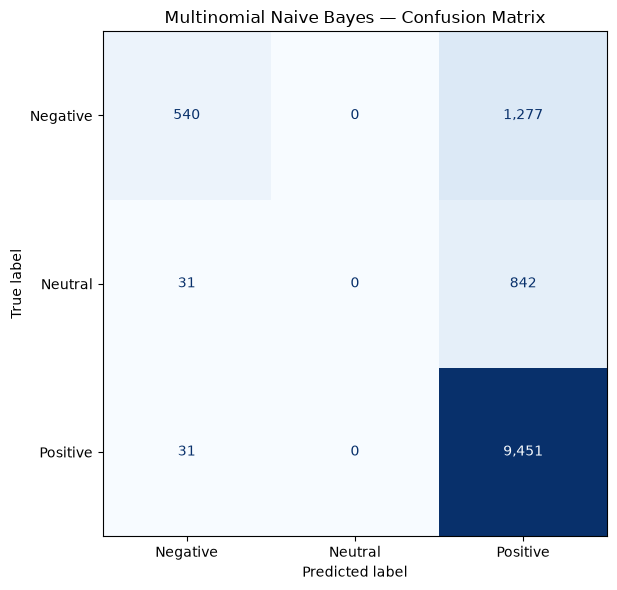

In [6]:
# Inspect how the model classified each sentiment class
labels = ["Negative", "Neutral", "Positive"]

cm_nb = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=labels,
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=labels,
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=",",
    colorbar=False,
)

plt.title("Multinomial Naive Bayes — Confusion Matrix")
plt.tight_layout()
plt.show()

In [7]:
# Train Logistic Regression with class balancing
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42,
)

lr_model.fit(X_train_tfidf, y_train)

# Predict the test set
y_pred_lr = lr_model.predict(X_test_tfidf)

print("Logistic Regression — Initial Results")
print("-" * 45)
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Macro-F1: {f1_score(y_test, y_pred_lr, average='macro'):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_lr,
        labels=["Negative", "Neutral", "Positive"],
        zero_division=0,
    )
)

Logistic Regression — Initial Results
---------------------------------------------
Accuracy: 0.8212
Macro-F1: 0.6434

Classification Report:
              precision    recall  f1-score   support

    Negative       0.68      0.80      0.74      1817
     Neutral       0.23      0.37      0.28       873
    Positive       0.95      0.87      0.91      9482

    accuracy                           0.82     12172
   macro avg       0.62      0.68      0.64     12172
weighted avg       0.86      0.82      0.84     12172



In [8]:
# Record baseline results for model comparison
results = [
    {
        "Model": "Multinomial Naive Bayes",
        "Accuracy": accuracy_score(y_test, y_pred_nb),
        "Macro-F1": f1_score(y_test, y_pred_nb, average="macro"),
    },
    {
        "Model": "Logistic Regression (balanced)",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "Macro-F1": f1_score(y_test, y_pred_lr, average="macro"),
    },
]

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="Macro-F1",
        ascending=False,
    ).round(4)
)

,Model,Accuracy,Macro-F1
1,Logistic Regression (balanced),0.8212,0.6434
0,Multinomial Naive Bayes,0.8208,0.4481


In [10]:
# Train Linear SVM with class balancing
svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42,
)

svm_model.fit(X_train_tfidf, y_train)

# Predict sentiment for unseen test reviews
y_pred_svm = svm_model.predict(X_test_tfidf)

print("Linear SVM — Initial Results")
print("-" * 45)
print(f"Accuracy: {accuracy_score(y_test, y_pred_svm):.4f}")
print(f"Macro-F1: {f1_score(y_test, y_pred_svm, average='macro'):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_svm,
        labels=["Negative", "Neutral", "Positive"],
        zero_division=0,
    )
)

Linear SVM — Initial Results
---------------------------------------------
Accuracy: 0.8585
Macro-F1: 0.6334

Classification Report:
              precision    recall  f1-score   support

    Negative       0.71      0.77      0.74      1817
     Neutral       0.29      0.19      0.23       873
    Positive       0.92      0.94      0.93      9482

    accuracy                           0.86     12172
   macro avg       0.64      0.63      0.63     12172
weighted avg       0.85      0.86      0.85     12172



In [11]:
results = [
    {
        "Model": "Multinomial Naive Bayes",
        "Accuracy": accuracy_score(y_test, y_pred_nb),
        "Macro-F1": f1_score(y_test, y_pred_nb, average="macro"),
    },
    {
        "Model": "Logistic Regression (balanced)",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "Macro-F1": f1_score(y_test, y_pred_lr, average="macro"),
    },
    {
        "Model": "Linear SVM (balanced)",
        "Accuracy": accuracy_score(y_test, y_pred_svm),
        "Macro-F1": f1_score(y_test, y_pred_svm, average="macro"),
    },
]

results_df = (
    pd.DataFrame(results)
    .sort_values("Macro-F1", ascending=False)
    .reset_index(drop=True)
)

display(results_df.round(4))

,Model,Accuracy,Macro-F1
0,Logistic Regression (balanced),0.8212,0.6434
1,Linear SVM (balanced),0.8585,0.6334
2,Multinomial Naive Bayes,0.8208,0.4481


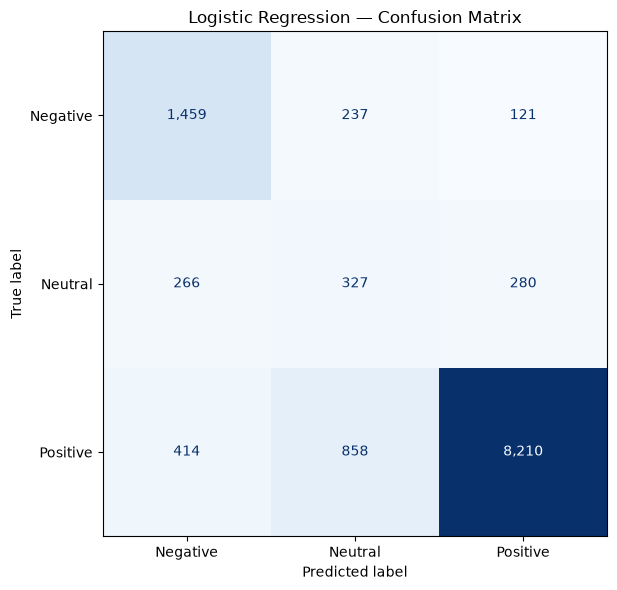

In [12]:
labels = ["Negative", "Neutral", "Positive"]

cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=labels,
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=labels,
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=",",
    colorbar=False,
)

plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

In [13]:
# Collect actual labels, predictions, and review text
error_df = pd.DataFrame({
    "review_text": X_test.to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": y_pred_lr,
})

# Keep only incorrect predictions
error_df = error_df[
    error_df["actual"] != error_df["predicted"]
].copy()

print("Total misclassified reviews:", len(error_df))

# Examine selected confusion patterns
error_pairs = [
    ("Negative", "Positive"),
    ("Neutral", "Positive"),
    ("Positive", "Neutral"),
]

for actual_label, predicted_label in error_pairs:
    examples = error_df[
        (error_df["actual"] == actual_label)
        & (error_df["predicted"] == predicted_label)
    ].head(5)

    print(f"\n{'=' * 15} {actual_label} -> {predicted_label} {'=' * 15}")

    for _, row in examples.iterrows():
        print(f"\nReview: {row['review_text'][:500]}")

Total misclassified reviews: 2176

=============== Negative -> Positive ===============

Review: Nat good because it charge a mobile (4000mah) only one time and the power bank capicity is 10000 mah

Review: Good quality cable but issue faced in product registration on boat website for warranty purpose

Review: Slippery inconvenient designed device that discharges soon. Large power banks are quite incomfortable. I won't recommend.

Review: This product little problem as diceplay lite outomatic up and down Etc

Review: Bal

=============== Neutral -> Positive ===============

Review: Although minor light bleeding problem exists, I am ok with it overall. Price dropped within few days of my purchase... this made me sad.

Review: Dont go for it if u r a selfie lover back is ok bt the fornt camera is very dissapointing i think in this price range realme 5 is far better than vivo u10

Review: Good

Review: The sound quality needs some improvement...

Review: Good and nice for small room and n

In [14]:
# Inspect the strongest learned TF-IDF features for each class
feature_names = tfidf.get_feature_names_out()
class_names = list(lr_model.classes_)

for class_index, class_name in enumerate(class_names):
    weights = lr_model.coef_[class_index]
    top_indices = weights.argsort()[-15:][::-1]

    print(f"\n{'=' * 12} {class_name} {'=' * 12}")

    for index in top_indices:
        print(f"{feature_names[index]:<30} {weights[index]:.3f}")


============ Negative ============
worst                          5.846
not                            5.592
return                         4.351
waste                          4.166
poor                           4.007
defective                      3.748
at all                         3.472
don buy                        3.322
even                           3.291
disappointed                   3.167
pathetic                       3.112
very bad                       2.964
don                            2.775
useless                        2.733
damaged                        2.723

============ Neutral ============
average                        2.419
but                            2.276
however                        2.240
not                            2.075
okay                           1.954
volume                         1.941
quality superb                 1.926
early                          1.858
is wrost                       1.853
weak                           1.850
okey

In [15]:
import joblib

# Create the model directory if it doesn't exist
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the fitted TF-IDF vectorizer and selected classifier
joblib.dump(tfidf, MODEL_DIR / "tfidf_vectorizer.joblib")
joblib.dump(lr_model, MODEL_DIR / "sentiment_model.joblib")

print("Saved model artifacts:")
print(MODEL_DIR / "tfidf_vectorizer.joblib")
print(MODEL_DIR / "sentiment_model.joblib")

Saved model artifacts:
c:\Users\91886\Python\product-review-sentiment\models\tfidf_vectorizer.joblib
c:\Users\91886\Python\product-review-sentiment\models\sentiment_model.joblib


In [1]:
for name in [
    "X_train", "X_test", "y_train", "y_test",
    "tfidf", "vectorizer", "tfidf_vectorizer",
    "train_df", "test_df"
]:
    print(f"{name}: {'available' if name in globals() else 'missing'}")

X_train: missing
X_test: missing
y_train: missing
y_test: missing
tfidf: missing
vectorizer: missing
tfidf_vectorizer: missing
train_df: missing
test_df: missing


In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the original dataset
df = pd.read_csv("../data/raw/amazon_reviews.csv")

# Reproduce the cleaning used in the earlier project
df = df.dropna(subset=["Review_text", "Own_Rating"]).copy()
df["Review_text"] = df["Review_text"].astype(str).str.strip()
df = df[df["Review_text"] != ""].copy()

valid_labels = ["Negative", "Neutral", "Positive"]
df = df[df["Own_Rating"].isin(valid_labels)].copy()

df["text"] = df["Review_text"]
df["label"] = df["Own_Rating"]

label2id = {"Negative": 0, "Neutral": 1, "Positive": 2}
df["label_id"] = df["label"].map(label2id)

# Recreate the 70/15/15 stratified split
train_df, temp_df = train_test_split(
    df[["text", "label", "label_id"]],
    test_size=0.30,
    random_state=42,
    stratify=df["label_id"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label_id"]
)

# Verify against the shared Colab test file
shared_test = pd.read_csv("../data/processed/shared_test.csv")

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Recreated test rows:", len(test_df))
print("Shared test rows:", len(shared_test))
print(
    "Test labels match:",
    test_df["label"].reset_index(drop=True).equals(
        shared_test["label"].reset_index(drop=True)
    )
)

Training rows: 42599
Validation rows: 9129
Recreated test rows: 9129
Shared test rows: 9129
Test labels match: True


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd
import time
from pathlib import Path

# Fit the vectorizer on training data only
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_features=100_000,
    sublinear_tf=True
)

X_train = tfidf_vectorizer.fit_transform(train_df["text"])
X_test = tfidf_vectorizer.transform(shared_test["text"])

y_train = train_df["label"]
y_test = shared_test["label"]

models = {
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    start = time.perf_counter()
    predictions = model.predict(X_test)
    elapsed = time.perf_counter() - start

    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(y_test, predictions, average="macro")

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro-F1": macro_f1,
        "Prediction time (seconds)": elapsed
    })

    print(f"\n=== {name} ===")
    print(classification_report(y_test, predictions, digits=4))

    # Save predictions for the final comparison
    safe_name = name.lower().replace(" ", "_")
    output = shared_test[["test_id", "label"]].copy()
    output["prediction"] = predictions

    output.to_csv(
        f"../data/processed/{safe_name}_predictions.csv",
        index=False
    )

# Save models and vectorizer for reproducibility
import joblib

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(tfidf_vectorizer, model_dir / "shared_tfidf_vectorizer.joblib")
joblib.dump(models["Naive Bayes"], model_dir / "naive_bayes_shared.joblib")
joblib.dump(models["Linear SVM"], model_dir / "linear_svm_shared.joblib")

print("\n=== Summary ===")
display(pd.DataFrame(results).round(4))


=== Naive Bayes ===
              precision    recall  f1-score   support

    Negative     0.9120    0.2737    0.4210      1363
     Neutral     0.0000    0.0000    0.0000       655
    Positive     0.8131    0.9970    0.8957      7111

    accuracy                         0.8175      9129
   macro avg     0.5750    0.4236    0.4389      9129
weighted avg     0.7695    0.8175    0.7606      9129



c:\Users\91886\Python\product-review-sentiment\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\91886\Python\product-review-sentiment\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\91886\Python\product-review-sentiment\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 


=== Linear SVM ===
              precision    recall  f1-score   support

    Negative     0.7102    0.7696    0.7387      1363
     Neutral     0.2751    0.1802    0.2177       655
    Positive     0.9250    0.9395    0.9322      7111

    accuracy                         0.8597      9129
   macro avg     0.6367    0.6298    0.6295      9129
weighted avg     0.8463    0.8597    0.8520      9129


=== Summary ===


,Model,Accuracy,Macro-F1,Prediction time (seconds)
0,Naive Bayes,0.8175,0.4389,0.0049
1,Linear SVM,0.8597,0.6295,0.0033


In [4]:
from sklearn.linear_model import LogisticRegression
import joblib
from pathlib import Path

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(X_train, y_train)

predictions = lr_model.predict(X_test)

print(classification_report(
    y_test,
    predictions,
    digits=4,
    zero_division=0
))

model_dir = Path("../models")
joblib.dump(lr_model, model_dir / "logistic_regression_shared.joblib")

print("Saved shared-split Logistic Regression model.")

              precision    recall  f1-score   support

    Negative     0.6832    0.7990    0.7366      1363
     Neutral     0.2388    0.3908    0.2965       655
    Positive     0.9556    0.8685    0.9100      7111

    accuracy                         0.8239      9129
   macro avg     0.6259    0.6861    0.6477      9129
weighted avg     0.8635    0.8239    0.8401      9129

Saved shared-split Logistic Regression model.


In [7]:

from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

# Paths relative to notebooks/02_model_training.ipynb
raw_path = Path("../data/raw/amazon_reviews.csv")
output_dir = Path("../data/processed/final_split")
output_dir.mkdir(parents=True, exist_ok=True)

# Load and clean the dataset
df = pd.read_csv(raw_path)

df = df.dropna(subset=["Review_text", "Own_Rating"]).copy()
df["text"] = df["Review_text"].astype(str).str.strip()
df = df[df["text"] != ""].copy()

valid_labels = ["Negative", "Neutral", "Positive"]
df = df[df["Own_Rating"].isin(valid_labels)].copy()

# Preserve original IDs and create consistent numeric labels
df["label"] = df["Own_Rating"]
label2id = {"Negative": 0, "Neutral": 1, "Positive": 2}
df["label_id"] = df["label"].map(label2id)

# First reserve 15% as the final test set
development_df, final_test_df = train_test_split(
    df,
    test_size=0.15,
    random_state=2026,
    stratify=df["label_id"]
)

# Split the remaining 85% into training and validation.
# This produces approximately 70% train, 15% validation, 15% test.
train_df, val_df = train_test_split(
    development_df,
    test_size=0.15 / 0.85,
    random_state=2026,
    stratify=development_df["label_id"]
)

# Save only the columns needed for reproducible experiments
columns_to_save = [
    "Unique_ID", "text", "label", "label_id"
]

train_df[columns_to_save].to_csv(
    output_dir / "train.csv", index=False
)
val_df[columns_to_save].to_csv(
    output_dir / "validation.csv", index=False
)
final_test_df[columns_to_save].to_csv(
    output_dir / "final_test.csv", index=False
)

# Save split configuration for reproducibility
split_info = {
    "random_state": 2026,
    "train_rows": len(train_df),
    "validation_rows": len(val_df),
    "final_test_rows": len(final_test_df),
    "label_mapping": label2id
}

pd.Series(split_info).to_json(
    output_dir / "split_info.json", indent=2
)

# Verify that the splits do not overlap
train_ids = set(train_df["Unique_ID"])
val_ids = set(val_df["Unique_ID"])
test_ids = set(final_test_df["Unique_ID"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("New split created successfully.")
print(f"Training rows:   {len(train_df):,}")
print(f"Validation rows: {len(val_df):,}")
print(f"Final test rows: {len(final_test_df):,}")
print("\nClass distribution (%):")

for name, split in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Final test", final_test_df)
]:
    print(f"\n{name}:")
    print(
        (split["label"].value_counts(normalize=True) * 100)
        .reindex(valid_labels)
        .round(2)
    )

print(f"\nFiles saved in: {output_dir.resolve()}")


New split created successfully.
Training rows:   42,599
Validation rows: 9,129
Final test rows: 9,129

Class distribution (%):

Train:
label
Negative    14.93
Neutral      7.17
Positive    77.90
Name: proportion, dtype: float64

Validation:
label
Negative    14.93
Neutral      7.17
Positive    77.89
Name: proportion, dtype: float64

Final test:
label
Negative    14.93
Neutral      7.17
Positive    77.89
Name: proportion, dtype: float64

Files saved in: C:\Users\91886\Python\product-review-sentiment\data\processed\final_split


In [8]:

from pathlib import Path
import json
import time
import joblib
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Paths
split_dir = Path("../data/processed/final_split")
model_dir = Path("../models/final_split")
model_dir.mkdir(parents=True, exist_ok=True)

# Load only training and validation data.
# We deliberately do not load final_test.csv in this step.
train_df = pd.read_csv(split_dir / "train.csv")
val_df = pd.read_csv(split_dir / "validation.csv")

X_train = train_df["text"].astype(str)
y_train = train_df["label"]
X_val = val_df["text"].astype(str)
y_val = val_df["label"]

# Fit TF-IDF on training text only
vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_features=100_000,
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)

# Define models with the previously chosen settings
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

validation_results = []
validation_predictions = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_tfidf, y_train)

    predictions = model.predict(X_val_tfidf)
    validation_predictions[name] = predictions

    validation_results.append({
        "Model": name,
        "Validation accuracy": accuracy_score(y_val, predictions),
        "Validation macro-F1": f1_score(
            y_val, predictions, average="macro"
        ),
        "Validation weighted-F1": f1_score(
            y_val, predictions, average="weighted"
        ),
        "Validation neutral-F1": f1_score(
            y_val, predictions,
            labels=["Neutral"], average="macro",
            zero_division=0
        )
    })

    # Save model checkpoints for the final evaluation
    joblib.dump(
        model,
        model_dir / f"{name.lower().replace(' ', '_')}.joblib"
    )

# Save the training-only-fitted vectorizer
joblib.dump(vectorizer, model_dir / "tfidf_vectorizer.joblib")

# Save validation metrics for comparison/model selection
validation_results_df = pd.DataFrame(validation_results)
validation_results_df = validation_results_df.sort_values(
    "Validation macro-F1", ascending=False
)
validation_results_df.to_csv(
    model_dir / "validation_results.csv", index=False
)

print("\nValidation results:")
display(validation_results_df.round(4))

print("\nDetailed validation reports:")
for name, predictions in validation_predictions.items():
    print(f"\n--- {name} ---")
    print(classification_report(
        y_val,
        predictions,
        labels=["Negative", "Neutral", "Positive"],
        zero_division=0
    ))

print(f"\nModels and results saved to: {model_dir.resolve()}")


Training Naive Bayes...
Training Logistic Regression...
Training Linear SVM...

Validation results:


,Model,Validation accuracy,Validation macro-F1,Validation weighted-F1,Validation neutral-F1
1,Logistic Regression,0.8221,0.6462,0.8377,0.3001
2,Linear SVM,0.8585,0.6295,0.8505,0.2216
0,Naive Bayes,0.8162,0.4344,0.7585,0.0000



Detailed validation reports:

--- Naive Bayes ---
              precision    recall  f1-score   support

    Negative       0.88      0.26      0.41      1363
     Neutral       0.00      0.00      0.00       655
    Positive       0.81      1.00      0.90      7111

    accuracy                           0.82      9129
   macro avg       0.57      0.42      0.43      9129
weighted avg       0.77      0.82      0.76      9129


--- Logistic Regression ---
              precision    recall  f1-score   support

    Negative       0.68      0.79      0.73      1363
     Neutral       0.24      0.39      0.30       655
    Positive       0.95      0.87      0.91      7111

    accuracy                           0.82      9129
   macro avg       0.62      0.68      0.65      9129
weighted avg       0.86      0.82      0.84      9129


--- Linear SVM ---
              precision    recall  f1-score   support

    Negative       0.72      0.76      0.74      1363
     Neutral       0.28      

In [9]:

from pathlib import Path
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, f1_score

split_dir = Path("../data/processed/final_split")
model_dir = Path("../models/final_split")

val_df = pd.read_csv(split_dir / "validation.csv")
X_val = val_df["text"].astype(str)
y_val = val_df["label"]

# Load models trained on the new training split
vectorizer = joblib.load(model_dir / "tfidf_vectorizer.joblib")

models = {
    "Naive Bayes": joblib.load(
        model_dir / "naive_bayes.joblib"
    ),
    "Logistic Regression": joblib.load(
        model_dir / "logistic_regression.joblib"
    ),
    "Linear SVM": joblib.load(
        model_dir / "linear_svm.joblib"
    )
}

# Warm up TF-IDF transformation
_ = vectorizer.transform(X_val.iloc[:100])

# Measure feature extraction separately
transform_times = []
for _ in range(3):
    start = time.perf_counter()
    X_val_tfidf = vectorizer.transform(X_val)
    transform_times.append(time.perf_counter() - start)

# Use the median of three full validation-set runs
transform_seconds = float(np.median(transform_times))

results = []

for name, model in models.items():
    # Warm-up prediction
    _ = model.predict(X_val_tfidf[:100])

    prediction_times = []
    predictions = None

    for _ in range(3):
        start = time.perf_counter()
        predictions = model.predict(X_val_tfidf)
        prediction_times.append(time.perf_counter() - start)

    predict_seconds = float(np.median(prediction_times))
    end_to_end_seconds = transform_seconds + predict_seconds

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro-F1": f1_score(
            y_val, predictions, average="macro"
        ),
        "Neutral-F1": f1_score(
            y_val, predictions,
            labels=["Neutral"], average="macro",
            zero_division=0
        ),
        "Feature extraction seconds": transform_seconds,
        "Prediction seconds": predict_seconds,
        "End-to-end seconds": end_to_end_seconds,
        "Reviews per second (prediction only)": (
            len(X_val) / predict_seconds
        ),
        "Milliseconds per review (prediction only)": (
            1000 * predict_seconds / len(X_val)
        )
    })

results_df = pd.DataFrame(results).sort_values(
    "Macro-F1", ascending=False
)

display(results_df.round(4))

output_path = model_dir / "traditional_validation_inference_speed.csv"
results_df.to_csv(output_path, index=False)

print(f"\nResults saved to: {output_path.resolve()}")
print(f"Validation examples: {len(X_val):,}")
print("Timing statistic: median of three full validation-set runs")


,Model,Accuracy,Macro-F1,Neutral-F1,Feature extraction seconds,Prediction seconds,End-to-end seconds,Reviews per second (prediction only),Milliseconds per review (prediction only)
1,Logistic Regression,0.8221,0.6462,0.3001,0.3922,0.0021,0.3943,4.385147e+06,0.0002
2,Linear SVM,0.8585,0.6295,0.2216,0.3922,0.0025,0.3947,3.659798e+06,0.0003
0,Naive Bayes,0.8162,0.4344,0.0000,0.3922,0.0034,0.3956,2.671016e+06,0.0004



Results saved to: C:\Users\91886\Python\product-review-sentiment\models\final_split\traditional_validation_inference_speed.csv
Validation examples: 9,129
Timing statistic: median of three full validation-set runs


In [10]:

from pathlib import Path
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, f1_score

# --------------------------------------------------
# 1. Load the existing validation data and models
# --------------------------------------------------
split_dir = Path("../data/processed/final_split")
model_dir = Path("../models/final_split")

val_df = pd.read_csv(split_dir / "validation.csv")
X_val = val_df["text"].astype(str)
y_val = val_df["label"]

vectorizer = joblib.load(model_dir / "tfidf_vectorizer.joblib")

models = {
    "Naive Bayes": joblib.load(model_dir / "naive_bayes.joblib"),
    "Logistic Regression": joblib.load(
        model_dir / "logistic_regression.joblib"
    ),
    "Linear SVM": joblib.load(model_dir / "linear_svm.joblib")
}

# --------------------------------------------------
# 2. Transform validation text once
# --------------------------------------------------
X_val_tfidf = vectorizer.transform(X_val)

# --------------------------------------------------
# 3. Benchmark repeated predictions
#    Use 20 repetitions to reduce timer noise.
# --------------------------------------------------
results = []

for name, model in models.items():

    # Warm-up run: excluded from timing
    _ = model.predict(X_val_tfidf)

    durations = []

    for repetition in range(20):
        start = time.perf_counter()
        predictions = model.predict(X_val_tfidf)
        elapsed = time.perf_counter() - start
        durations.append(elapsed)

    median_seconds = float(np.median(durations))
    total_reviews = len(X_val)

    results.append({
        "Model": name,
        "Validation accuracy": accuracy_score(y_val, predictions),
        "Validation macro-F1": f1_score(
            y_val, predictions, average="macro"
        ),
        "Validation Neutral-F1": f1_score(
            y_val,
            predictions,
            labels=["Neutral"],
            average="macro",
            zero_division=0
        ),
        "Median prediction seconds": median_seconds,
        "Reviews per second": total_reviews / median_seconds,
        "Milliseconds per review": (
            1000 * median_seconds / total_reviews
        ),
        "Timed repetitions": len(durations)
    })

results_df = pd.DataFrame(results)

# --------------------------------------------------
# 4. Save results without overwriting earlier files
# --------------------------------------------------
output_path = model_dir / "traditional_validation_speed_stable.csv"
results_df.to_csv(output_path, index=False)

print("TRADITIONAL MODEL SPEED BENCHMARK")
print(f"Validation reviews: {len(X_val):,}")
print("TF-IDF transformation: excluded from prediction timing")
print("Timing method: median of 20 full-batch predictions")
print("\nResults:")
display(results_df.round(6))

print(f"\nSaved to: {output_path.resolve()}")


TRADITIONAL MODEL SPEED BENCHMARK
Validation reviews: 9,129
TF-IDF transformation: excluded from prediction timing
Timing method: median of 20 full-batch predictions

Results:


,Model,Validation accuracy,Validation macro-F1,Validation Neutral-F1,Median prediction seconds,Reviews per second,Milliseconds per review,Timed repetitions
0,Naive Bayes,0.816190,0.434445,0.000000,0.004810,1.897743e+06,0.000527,20
1,Logistic Regression,0.822105,0.646202,0.300058,0.001907,4.787979e+06,0.000209,20
2,Linear SVM,0.858473,0.629480,0.221607,0.001885,4.842329e+06,0.000207,20



Saved to: C:\Users\91886\Python\product-review-sentiment\models\final_split\traditional_validation_speed_stable.csv


In [11]:

from pathlib import Path
import pandas as pd

final_test_path = Path("../data/processed/final_split/final_test.csv")
old_test_path = Path("../data/processed/shared_test.csv")

final_test = pd.read_csv(final_test_path)

print("New final-test rows:", len(final_test))

if not old_test_path.exists():
    print("\nEarlier shared test file not found at:")
    print(old_test_path.resolve())
    print("We cannot complete this overlap check from this file.")
else:
    old_test = pd.read_csv(old_test_path)

    # Compare original dataset IDs where available.
    if "Unique_ID" in final_test.columns and "Unique_ID" in old_test.columns:
        overlap = set(final_test["Unique_ID"]) & set(old_test["Unique_ID"])
        print("Earlier shared-test rows:", len(old_test))
        print("Overlapping Unique_IDs:", len(overlap))
        print(
            "Percentage of new final test overlapping old shared test:",
            round(100 * len(overlap) / len(final_test), 2), "%"
        )
    else:
        print("Unique_ID column missing from one of the files.")
        print("New test columns:", final_test.columns.tolist())
        print("Old test columns:", old_test.columns.tolist())


New final-test rows: 9129
Unique_ID column missing from one of the files.
New test columns: ['Unique_ID', 'text', 'label', 'label_id']
Old test columns: ['test_id', 'text', 'label', 'label_id']


In [12]:

from pathlib import Path
import pandas as pd
import hashlib

final_test_path = Path("../data/processed/final_split/final_test.csv")
old_test_path = Path("../data/processed/shared_test.csv")

final_test = pd.read_csv(final_test_path)
old_test = pd.read_csv(old_test_path)

def normalize_text(text):
    return " ".join(str(text).split()).strip().casefold()

# Create normalized text keys for comparison
final_test["text_key"] = final_test["text"].map(normalize_text)
old_test["text_key"] = old_test["text"].map(normalize_text)

# Check exact normalized-text overlap
old_texts = set(old_test["text_key"])
overlap_mask = final_test["text_key"].isin(old_texts)
overlap_count = int(overlap_mask.sum())

# Also check whether overlapping text has the same label
old_label_map = (
    old_test.drop_duplicates("text_key")
    .set_index("text_key")["label"]
    .to_dict()
)

overlap_rows = final_test.loc[overlap_mask, ["text_key", "label"]].copy()
overlap_rows["old_label"] = overlap_rows["text_key"].map(old_label_map)

same_label_count = int(
    (overlap_rows["label"] == overlap_rows["old_label"]).sum()
)

print("New final-test rows:", len(final_test))
print("Earlier shared-test rows:", len(old_test))
print("Exact normalized-text overlaps:", overlap_count)
print(
    "Percentage of new final test overlapping old shared test:",
    round(100 * overlap_count / len(final_test), 2), "%"
)
print("Overlaps with matching labels:", same_label_count)
print(
    "Overlaps with different labels:",
    overlap_count - same_label_count
)


New final-test rows: 9129
Earlier shared-test rows: 9129
Exact normalized-text overlaps: 2643
Percentage of new final test overlapping old shared test: 28.95 %
Overlaps with matching labels: 2524
Overlaps with different labels: 119


In [13]:

from pathlib import Path
import pandas as pd

final_test_path = Path("../data/processed/final_split/final_test.csv")
old_test_path = Path("../data/processed/shared_test.csv")
audit_path = Path("../data/processed/final_split/overlap_label_audit.csv")

final_test = pd.read_csv(final_test_path)
old_test = pd.read_csv(old_test_path)

def normalize_text(text):
    return " ".join(str(text).split()).strip().casefold()

final_test["text_key"] = final_test["text"].map(normalize_text)
old_test["text_key"] = old_test["text"].map(normalize_text)

# Keep every old label associated with each normalized text.
old_labels_by_text = (
    old_test.groupby("text_key")["label"]
    .agg(lambda labels: sorted(set(labels)))
    .to_dict()
)

# Find new-test rows whose text occurs in the old test
overlap = final_test[
    final_test["text_key"].isin(old_labels_by_text)
].copy()

overlap["old_labels"] = overlap["text_key"].map(old_labels_by_text)
overlap["old_label_count"] = overlap["old_labels"].map(len)

# Different means the new label is absent from the set of old labels
overlap["label_disagrees"] = overlap.apply(
    lambda row: row["label"] not in row["old_labels"], axis=1
)

conflicts = overlap[overlap["label_disagrees"]].copy()

print("Overlapping new-test rows:", len(overlap))
print("Rows with label disagreements:", len(conflicts))
print(
    "Conflicting rows whose old text has multiple labels:",
    int((conflicts["old_label_count"] > 1).sum())
)

# Save the full disagreement audit, including the text and source ID
conflicts[
    ["Unique_ID", "text", "label", "old_labels", "old_label_count"]
].to_csv(audit_path, index=False)

print("\nFirst 10 disagreements:")
display(
    conflicts[
        ["Unique_ID", "text", "label", "old_labels", "old_label_count"]
    ].head(10)
)

print("\nFull audit saved to:", audit_path.resolve())


Overlapping new-test rows: 2643
Rows with label disagreements: 46
Conflicting rows whose old text has multiple labels: 2

First 10 disagreements:


,Unique_ID,text,label,old_labels,old_label_count
114,113465,Average quality,Neutral,[Negative],1
282,115382,Battery back up is not good,Negative,[Neutral],1
293,164574,Very slow,Negative,[Positive],1
323,162210,Value of money,Neutral,[Positive],1
335,147741,Not very good,Neutral,[Positive],1
1126,115405,Battery backup,Negative,[Positive],1
1432,118506,Brand,Neutral,[Positive],1
1584,154867,Sound is not good,Negative,[Positive],1
1683,113427,Average phone,Neutral,[Positive],1
2115,118055,Better in this price,Positive,[Neutral],1



Full audit saved to: C:\Users\91886\Python\product-review-sentiment\data\processed\final_split\overlap_label_audit.csv


In [14]:

from pathlib import Path
import pandas as pd

raw_path = Path("../data/raw/amazon_reviews.csv")
audit_path = Path("../data/processed/final_split/overlap_label_audit.csv")
output_path = Path(
    "../data/processed/final_split/original_source_conflict_audit.csv"
)

raw = pd.read_csv(raw_path)
conflicts = pd.read_csv(audit_path)

def normalize_text(text):
    return " ".join(str(text).split()).strip().casefold()

raw["text_key"] = raw["Review_text"].fillna("").map(normalize_text)
conflicts["text_key"] = conflicts["text"].fillna("").map(normalize_text)

# Keep original records for the conflicting review texts
source_matches = raw[
    raw["text_key"].isin(set(conflicts["text_key"]))
][
    ["Unique_ID", "Review_text", "Rating", "Own_Rating", "Category", "text_key"]
].copy()

# Attach the conflicting final-test label for comparison
source_matches = source_matches.merge(
    conflicts[["text_key", "label", "old_labels"]],
    on="text_key",
    how="left"
)

source_matches["source_label_matches_new"] = (
    source_matches["Own_Rating"] == source_matches["label"]
)

source_matches.to_csv(output_path, index=False)

print("Conflicting text examples:", conflicts["text_key"].nunique())
print("Original source rows matched:", len(source_matches))
print(
    "Unique original IDs:",
    source_matches["Unique_ID"].nunique()
)
print(
    "Original rows whose Own_Rating matches the new label:",
    int(source_matches["source_label_matches_new"].sum())
)
print(
    "Original rows whose Own_Rating differs from the new label:",
    int((~source_matches["source_label_matches_new"]).sum())
)

print("\nFirst 15 matched original records:")
display(
    source_matches[
        [
            "Unique_ID", "Review_text", "Rating", "Own_Rating",
            "Category", "label", "old_labels"
        ]
    ].head(15)
)

print("\nFull audit saved to:", output_path.resolve())


Conflicting text examples: 37
Original source rows matched: 1836
Unique original IDs: 1578
Original rows whose Own_Rating matches the new label: 138
Original rows whose Own_Rating differs from the new label: 1698

First 15 matched original records:


,Unique_ID,Review_text,Rating,Own_Rating,Category,label,old_labels
0,128968,Good phone,5,Positive,smartTv,Neutral,['Positive']
1,129755,Good product,5,Positive,mobile,Negative,"['Neutral', 'Positive']"
2,145383,Nice phone,5,Positive,mobile accessories,Negative,['Positive']
3,129580,Good product,4,Positive,smartTv,Negative,"['Neutral', 'Positive']"
4,129031,Good phone,5,Positive,mobile,Neutral,['Positive']
5,145300,Nice phone,4,Positive,smartTv,Negative,['Positive']
6,141703,Like,5,Positive,mobile,Neutral,['Positive']
7,141703,Like,5,Positive,mobile,Neutral,['Positive']
8,129848,Good product,5,Positive,mobile accessories,Negative,"['Neutral', 'Positive']"
9,145414,Nice phone,5,Positive,smartTv,Negative,['Positive']



Full audit saved to: C:\Users\91886\Python\product-review-sentiment\data\processed\final_split\original_source_conflict_audit.csv


In [15]:

from pathlib import Path
import pandas as pd

raw = pd.read_csv("../data/raw/amazon_reviews.csv")
final_test = pd.read_csv(
    "../data/processed/final_split/final_test.csv"
)
old_test = pd.read_csv(
    "../data/processed/shared_test.csv"
)

# Compare source labels by unique review ID, not text
source = raw[["Unique_ID", "Review_text", "Rating", "Own_Rating"]].copy()
source["Unique_ID"] = source["Unique_ID"].astype(str)

final_test["Unique_ID"] = final_test["Unique_ID"].astype(str)

merged = final_test.merge(
    source,
    on="Unique_ID",
    how="left",
    suffixes=("_split", "_source"),
    validate="many_to_one"
)

print("Final-test rows:", len(final_test))
print("Rows matched to original source:", merged["Own_Rating"].notna().sum())
print(
    "Rows where split label matches original Own_Rating:",
    (merged["label"] == merged["Own_Rating"]).sum()
)
print(
    "Rows where split label differs from original Own_Rating:",
    (merged["label"] != merged["Own_Rating"]).sum()
)

print("\nFirst 10 mismatches:")
display(
    merged.loc[
        merged["label"] != merged["Own_Rating"],
        ["Unique_ID", "text", "label", "Review_text", "Rating", "Own_Rating"]
    ].head(10)
)


Final-test rows: 9129
Rows matched to original source: 9129
Rows where split label matches original Own_Rating: 9129
Rows where split label differs from original Own_Rating: 0

First 10 mismatches:


,Unique_ID,text,label,Review_text,Rating,Own_Rating


In [17]:
from pathlib import Path
import joblib
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

ROOT = Path.cwd()

# If the notebook's working directory isn't the project root,
# locate the root using the expected project folder.
if not (ROOT / "data/processed/final_split/final_test.csv").exists():
    ROOT = Path("C:/Users/91886/Python/product-review-sentiment")

test_path = ROOT / "data/processed/final_split/final_test.csv"
model_dir = ROOT / "models/final_split"

test_df = pd.read_csv(test_path)

vectorizer = joblib.load(model_dir / "tfidf_vectorizer.joblib")

models = {
    "Naive Bayes": joblib.load(model_dir / "naive_bayes.joblib"),
    "Logistic Regression": joblib.load(
        model_dir / "logistic_regression.joblib"
    ),
    "Linear SVM": joblib.load(model_dir / "linear_svm.joblib"),
}

label_names = ["Negative", "Neutral", "Positive"]
label2id = {label: i for i, label in enumerate(label_names)}

X_test = vectorizer.transform(test_df["text"].fillna("").astype(str))
y_true = test_df["label"].map(label2id).to_numpy()

results = []

for name, model in models.items():
    y_pred = pd.Series(model.predict(X_test)).map(label2id).to_numpy()

    report = classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=label_names,
        output_dict=True,
        zero_division=0
    )

    results.append({
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
        "negative_f1": report["Negative"]["f1-score"],
        "neutral_f1": report["Neutral"]["f1-score"],
        "positive_f1": report["Positive"]["f1-score"],
    })

    print(f"\n{'=' * 50}\n{name}\n{'=' * 50}")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=label_names,
        zero_division=0
    ))
    print("Confusion matrix:")
    print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2]))

results_df = pd.DataFrame(results)
print("\nFINAL-TEST TRADITIONAL MODEL COMPARISON")
print(results_df.round(4).to_string(index=False))

output_path = ROOT / "reports" / "traditional_final_test_results.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
results_df.to_csv(output_path, index=False)

print(f"\nSaved results to: {output_path}")


Naive Bayes
              precision    recall  f1-score   support

    Negative       0.88      0.26      0.40      1363
     Neutral       0.00      0.00      0.00       655
    Positive       0.81      1.00      0.90      7111

    accuracy                           0.82      9129
   macro avg       0.56      0.42      0.43      9129
weighted avg       0.76      0.82      0.76      9129

Confusion matrix:
[[ 357    0 1006]
 [  27    0  628]
 [  22    0 7089]]

Logistic Regression
              precision    recall  f1-score   support

    Negative       0.67      0.80      0.73      1363
     Neutral       0.22      0.35      0.27       655
    Positive       0.95      0.86      0.90      7111

    accuracy                           0.82      9129
   macro avg       0.61      0.67      0.63      9129
weighted avg       0.86      0.82      0.83      9129

Confusion matrix:
[[1094  182   87]
 [ 210  231  214]
 [ 341  652 6118]]

Linear SVM
              precision    recall  f1-score   

In [18]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "reports").exists():
    ROOT = Path("C:/Users/91886/Python/product-review-sentiment")

comparison = pd.DataFrame([
    {
        "model": "Naive Bayes",
        "accuracy": 0.8156,
        "macro_f1": 0.4330,
        "weighted_f1": 0.7577,
        "negative_f1": 0.4036,
        "neutral_f1": 0.0000,
        "positive_f1": 0.8954,
    },
    {
        "model": "Logistic Regression",
        "accuracy": 0.8153,
        "macro_f1": 0.6335,
        "weighted_f1": 0.8323,
        "negative_f1": 0.7274,
        "neutral_f1": 0.2686,
        "positive_f1": 0.9044,
    },
    {
        "model": "Linear SVM",
        "accuracy": 0.8611,
        "macro_f1": 0.6352,
        "weighted_f1": 0.8542,
        "negative_f1": 0.7447,
        "neutral_f1": 0.2281,
        "positive_f1": 0.9328,
    },
    {
        "model": "BERT - Baseline",
        "accuracy": 0.8956,
        "macro_f1": 0.6504,
        "weighted_f1": 0.8761,
        "negative_f1": 0.8116,
        "neutral_f1": 0.1876,
        "positive_f1": 0.9519,
    },
    {
        "model": "BERT - Class-weighted",
        "accuracy": 0.8557,
        "macro_f1": 0.7083,
        "weighted_f1": 0.8706,
        "negative_f1": 0.7975,
        "neutral_f1": 0.3993,
        "positive_f1": 0.9280,
    },
])

output_path = ROOT / "reports" / "final_model_comparison.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
comparison.to_csv(output_path, index=False)

print(comparison.round(4).to_string(index=False))
print(f"\nSaved to: {output_path}")

                model  accuracy  macro_f1  weighted_f1  negative_f1  neutral_f1  positive_f1
          Naive Bayes    0.8156    0.4330       0.7577       0.4036      0.0000       0.8954
  Logistic Regression    0.8153    0.6335       0.8323       0.7274      0.2686       0.9044
           Linear SVM    0.8611    0.6352       0.8542       0.7447      0.2281       0.9328
      BERT - Baseline    0.8956    0.6504       0.8761       0.8116      0.1876       0.9519
BERT - Class-weighted    0.8557    0.7083       0.8706       0.7975      0.3993       0.9280

Saved to: C:\Users\91886\Python\product-review-sentiment\reports\final_model_comparison.csv


In [19]:
from pathlib import Path

ROOT = Path(
    r"C:\Users\91886\Python\product-review-sentiment"
)

paths_to_check = [
    "data/raw/amazon_reviews.csv",
    "data/processed/final_split/train.csv",
    "data/processed/final_split/validation.csv",
    "data/processed/final_split/final_test.csv",
    "models/final_split/naive_bayes.joblib",
    "models/final_split/logistic_regression.joblib",
    "models/final_split/linear_svm.joblib",
    "models/final_split/tfidf_vectorizer.joblib",
    "reports/final_model_comparison.csv",
    "reports/traditional_final_test_results.csv",
    "README.md",
    "app.py",
    "requirements.txt",
]

for relative_path in paths_to_check:
    path = ROOT / relative_path
    status = "FOUND" if path.exists() else "MISSING"
    size = f" ({path.stat().st_size:,} bytes)" if path.is_file() else ""
    print(f"{status:7} {relative_path}{size}")

FOUND   data/raw/amazon_reviews.csv (11,754,959 bytes)
FOUND   data/processed/final_split/train.csv (6,841,180 bytes)
FOUND   data/processed/final_split/validation.csv (1,516,960 bytes)
FOUND   data/processed/final_split/final_test.csv (1,504,507 bytes)
FOUND   models/final_split/naive_bayes.joblib (4,396,143 bytes)
FOUND   models/final_split/logistic_regression.joblib (2,198,687 bytes)
FOUND   models/final_split/linear_svm.joblib (2,198,555 bytes)
FOUND   models/final_split/tfidf_vectorizer.joblib (3,673,547 bytes)
FOUND   reports/final_model_comparison.csv (363 bytes)
FOUND   reports/traditional_final_test_results.csv (445 bytes)
FOUND   README.md (0 bytes)
FOUND   app.py (2,571 bytes)
FOUND   requirements.txt (123 bytes)


In [20]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path(r"C:\Users\91886\Python\product-review-sentiment")
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

# Read the consolidated comparison
comparison = pd.read_csv(REPORTS / "final_model_comparison.csv")

# Record the exact split sizes and label distributions
split_files = {
    "train": ROOT / "data/processed/final_split/train.csv",
    "validation": ROOT / "data/processed/final_split/validation.csv",
    "final_test": ROOT / "data/processed/final_split/final_test.csv",
}

split_summary = {}

for split_name, file_path in split_files.items():
    df = pd.read_csv(file_path)
    split_summary[split_name] = {
        "rows": int(len(df)),
        "label_distribution": {
            str(label): int(count)
            for label, count in df["label"].value_counts().items()
        },
        "label_proportions": {
            str(label): round(float(prop), 6)
            for label, prop in df["label"].value_counts(normalize=True).items()
        },
    }

summary = {
    "project_title": "Product Review Classification Using Sentiment Analysis and NLP Models",
    "dataset": "Amazon customer product reviews from Zenodo record 3549704",
    "target": "Three-class sentiment label: Negative, Neutral, Positive",
    "evaluation_note": (
        "The final-test split was partly exposed during earlier development. "
        "Disclose this limitation; do not describe the split as a completely "
        "untouched holdout."
    ),
    "splits": split_summary,
    "model_results": comparison.to_dict(orient="records"),
}

output_path = REPORTS / "experiment_summary.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print(json.dumps(split_summary, indent=2))
print(f"\nSaved experiment summary to: {output_path}")

{
  "train": {
    "rows": 42599,
    "label_distribution": {
      "Positive": 33185,
      "Negative": 6360,
      "Neutral": 3054
    },
    "label_proportions": {
      "Positive": 0.779009,
      "Negative": 0.149299,
      "Neutral": 0.071692
    }
  },
  "validation": {
    "rows": 9129,
    "label_distribution": {
      "Positive": 7111,
      "Negative": 1363,
      "Neutral": 655
    },
    "label_proportions": {
      "Positive": 0.778946,
      "Negative": 0.149304,
      "Neutral": 0.071749
    }
  },
  "final_test": {
    "rows": 9129,
    "label_distribution": {
      "Positive": 7111,
      "Negative": 1363,
      "Neutral": 655
    },
    "label_proportions": {
      "Positive": 0.778946,
      "Negative": 0.149304,
      "Neutral": 0.071749
    }
  }
}

Saved experiment summary to: C:\Users\91886\Python\product-review-sentiment\reports\experiment_summary.json
